
SVM Performance Comparison
Kernel  Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)  Training Time (s)
linear         81.25          82.00       81.74         81.79               0.45
  poly         74.92          82.16       75.85         77.07               0.92
   rbf         82.17          82.28       82.61         82.38               0.71

Best Kernel: rbf


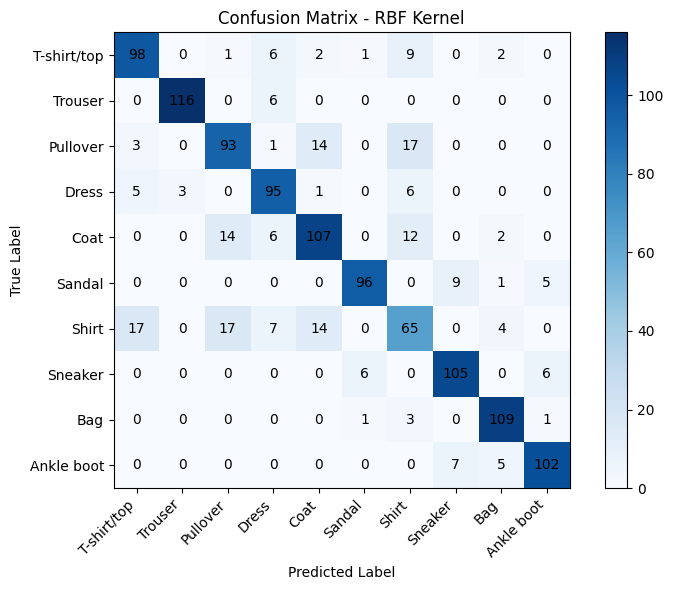

In [5]:

from tensorflow.keras.datasets import fashion_mnist
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
import time

# Load Fashion MNIST dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Flatten images
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Reduce dataset size
X_train = X_train[:2000]
y_train = y_train[:2000]
X_test = X_test[:1200]
y_test = y_test[:1200]

# Standardize dataset
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Compare SVM kernels
kernels = ['linear', 'poly', 'rbf']
results = []
predictions = {}

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    predictions[kernel] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    results.append([
        kernel, accuracy * 100, precision * 100,
        recall * 100, f1 * 100, train_time
    ])

# Display performance comparison
results_df = pd.DataFrame(
    results,
    columns=['Kernel', 'Accuracy (%)', 'Precision (%)',
             'Recall (%)', 'F1-score (%)', 'Training Time (s)']
)

print("\nSVM Performance Comparison")
print(results_df.round(2).to_string(index=False))

# Find best kernel
best_kernel = results_df.loc[
    results_df['Accuracy (%)'].idxmax(), 'Kernel'
]
print("\nBest Kernel:", best_kernel)

# Plot confusion matrix
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

cm = confusion_matrix(y_test, predictions[best_kernel])

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - " + best_kernel.upper() + " Kernel")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()
